In [ ]:
# Cell 1: Setup and imports
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'  # You can change to 'jax' or 'torch' if preferred

import numpy as np
import keras
import sentencepiece as spm

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.13.2
Keras backend: tensorflow


In [ ]:
# Cell 2: Load and prepare text data
# Load the Kalevala text
with open('./jane_austen_pride_and_prejudice_clean.txt', 'r', encoding='utf-8-sig') as file:
    text = file.read()

print(f"Text length: {len(text)} characters")
print(f"First 200 characters: {text[:200]}")

Text length: 684046 characters
First 200 characters: It is a truth universally acknowledged, that a single man in possession of a good fortune must be in want of a wife.

However little known the feelings or views of such a man may be on his first enter


In [ ]:
# Cell 3: Train SentencePiece model
# Save text to a temporary file for SentencePiece training
temp_file = 'pride_and_prejudice_temp.txt'
with open(temp_file, 'w', encoding='utf-8') as f:
    f.write(text)

# Train SentencePiece model (tokenizer?)
vocab_size = 12000  # You can adjust this based on your needs | Kokeilut: 1. 10000, 2. 11000, 3. 8000, 4. 6000, 5. 10000?, 6. 12000
model_prefix = 'pride_and_prejudice_sp'

spm.SentencePieceTrainer.train(
    input=temp_file,
    model_prefix=model_prefix,
    vocab_size=vocab_size,
    character_coverage=1.0,  # 1.0 for English and most other European languagaes (usually)
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

# Load the trained tokenizer
sp = spm.SentencePieceProcessor()
sp.load(f"{model_prefix}.model")

# Test tokenization
test_text = "Elizabeth, when Mr. Darcy gave her the letter, did not expect it to contain a renewal of his offers, she had formed no expectation at all of its contents."
tokens = sp.encode_as_pieces(test_text)
print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp.get_piece_size()}")

Tokenized example: ['▁Elizabeth', ',', '▁when', '▁Mr', '.', '▁Darcy', '▁gave', '▁her', '▁the', '▁letter', ',', '▁did', '▁not', '▁expect', '▁it', '▁to', '▁contain', '▁a', '▁renewal', '▁of', '▁his', '▁offers', ',', '▁she', '▁had', '▁formed', '▁no', '▁expectation', '▁at', '▁all', '▁of', '▁its', '▁contents', '.']
Vocabulary size: 12000


Nopeus vs. laatu: Kuinka pieneksi voit tehdä mallin (embedding-koko, attention-päiden määrä, kerrosten määrä) niin että koulutus on nopeaa, mutta tulos on vielä järkevää?

Maksimilaatu: Miten suuri malli tarvitaan parhaan tuloksen saavuttamiseksi — ja mitä se maksaa koulutusajassa?

Säädettäviä hyperparametreja ovat ainakin tekstinäytteen pituus (seq_length), Transformer-blokkien määrä (num_layers), upotusavaruuden dimensio (embed_dim), sanaston koko (vocab_size) ja fully connected -kerroksen leveys (ff_dim, usein tosin 2*embed_dim)

Tekstiä generoitaessa voi kokeilla eri arvoja lämpotila-asetukselle (temperature): 1.0 on normaali, suurempi arvo lisää satunnaisuutta, lähellä nollaa vähentää satunnaisuutta

Kokeilut:

1. Vertailukohde: suht kevyt kouluttaa, laatu ok

2. Hitaampi kouluttaa, monipuolisempi sanasto --> mielenkiintoisempia tuotoksia, mutta en tiedä oliko laatu kovinkaan paljon parempi

3. Nopeampi kouluttaa, vähemmän sanastoa, enemmän "virheitä" ja keskeneräisyyttä

4. Todella nopea kouluttaa, sanasto heikompi, kirjoittajan "tyyli" vaikuttaa häviävän hiukan, keskeneräisyyttä ja virheitä

5. Hitaampi kouluttaa, sanastoa paljon, tyylitellympi kieli, ei yhtä paljon virheitä

6. Todella hidas kouluttaa, sanastoa paljon, teksti aika epämääräistä

In [ ]:
# Cell 4: Prepare training data
# Tokenize the text
seq_length = 32 #Kokeilut: 1. 64, 2. 128, 3. 32, 4. 16, 5. 16, 6. 32
pieces = sp.encode_as_ids(text)
print(f"Total tokens: {len(pieces)}")

# Create sequences
sequences = []
for i in range(0, len(pieces) - seq_length):
    # Input: first seq_length tokens, Target: next seq_length tokens (shifted by 1)
    sequences.append(pieces[i:i+seq_length+1])

# Convert to NumPy arrays
sequences = np.array(sequences)
inputs = sequences[:, :-1]  # All tokens except the last one
targets = sequences[:, 1:]  # All tokens except the first one

print(f"Number of sequences: {len(sequences)}")
print(f"Input shape: {inputs.shape}")
print(f"Target shape: {targets.shape}")

# Split into training and validation sets: the first 90 % of the text for training,
# the rest for validation. Neighbouring windows share 63 of their 64 tokens, so a
# random split would put almost the same windows in both sets. Skipping seq_length
# windows at the split point leaves no shared tokens between the sets.
split = int(0.9 * len(sequences))
train_inputs, train_targets = inputs[:split], targets[:split]
val_inputs, val_targets = inputs[split + seq_length:], targets[split + seq_length:]

Total tokens: 144450
Number of sequences: 144418
Input shape: (144418, 32)
Target shape: (144418, 32)


In [ ]:
# Cell 5: Define the model
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding

# Define model parameters
embed_dim = 454  # Kokeilut: 1. 192, 2. 200, 3. 86, 4. 44, 5. 324, 6. 454
num_heads = 12  # Kokeilut: 1. 4, 2. 6, 3. 2, 4. 1, 5. 8, 6. 12
ff_dim = 908  # Kokeilut: 1. 384, 2. 400, 3. 172, 4. 88, 5. 648, 6. 908
num_layers = 7  # Kokeilut: 1. 2, 2. 3, 3. 1, 4. 1, 5. 5, 6. 7

# Create the model
inputs = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)

# Add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# Transformer blocks
for _ in range(num_layers):
    # Multi-head attention with causal mask
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    # Feed-forward network
    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# Final output layer
outputs = keras.layers.Dense(sp.get_piece_size())(x)

# Create model
model = keras.Model(inputs=inputs, outputs=outputs)

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

Model: "functional_31"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_24      │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_7         │ (None, 32, 454)   │  5,448,000 │ input_layer_24[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_41 (Add)        │ (None, 32, 454)   │          0 │ embedding_7[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 32, 454)   │    808,090 │ add_41[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_41[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_42 (Add)        │ (None, 32, 454)   │          0 │ add_41[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 32, 454)   │        908 │ add_42[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_17       │ (None, 32, 454)   │    825,826 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_43 (Add)        │ (None, 32, 454)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_17[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 32, 454)   │        908 │ add_43[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 32, 454)   │    808,090 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_44 (Add)        │ (None, 32, 454)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 32, 454)   │        908 │ add_44[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_18       │ (None, 32, 454)   │    825,826 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_45 (Add)        │ (None, 32, 454)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_18[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 32, 454)   │        908 │ add_45[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 32, 454)   │    808,090 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_46 (Add)        │ (None, 32, 454)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten

 Total params: 22,358,124 (85.29 MB)

 Trainable params: 22,358,124 (85.29 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Cell 6: Train the model
batch_size = 128
epochs = 100

history = model.fit(
    train_inputs, train_targets,
    validation_data=(val_inputs, val_targets),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('pride_and_prejudice_best_model.keras', save_best_only=True)
    ]
)

Epoch 1/100
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 366s 319ms/step - accuracy: 0.0616 - loss: 6.2535 - val_accuracy: 0.0607 - val_loss: 6.2980 - learning_rate: 3.0000e-04
Epoch 2/100
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 295s 290ms/step - accuracy: 0.0617 - loss: 6.2097 - val_accuracy: 0.0607 - val_loss: 6.3169 - learning_rate: 3.0000e-04
Epoch 3/100
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 294s 290ms/step - accuracy: 0.0617 - loss: 6.2027 - val_accuracy: 0.0607 - val_loss: 6.3196 - learning_rate: 1.5000e-04
Epoch 4/100
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 302s 297ms/step - accuracy: 0.0861 - loss: 5.8325 - val_accuracy: 0.1205 - val_loss: 5.3764 - learning_rate: 7.5000e-05
Epoch 5/100
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 305s 300ms/step - accuracy: 0.1548 - loss: 4.8438 - val_accuracy: 0.1498 - val_loss: 5.1573 - learning_rate: 7.5000e-05
Epoch 6/100
1016/1016 ━━━━━━━━━━━━━━━━━━━━ 305s 300ms/step - accuracy: 0.1762 - loss: 4.5354 - val_accuracy: 0.1564 - val_loss: 5.1175 - learning_rate: 7.5000e-05
Epoch 7/100
1016/1016 

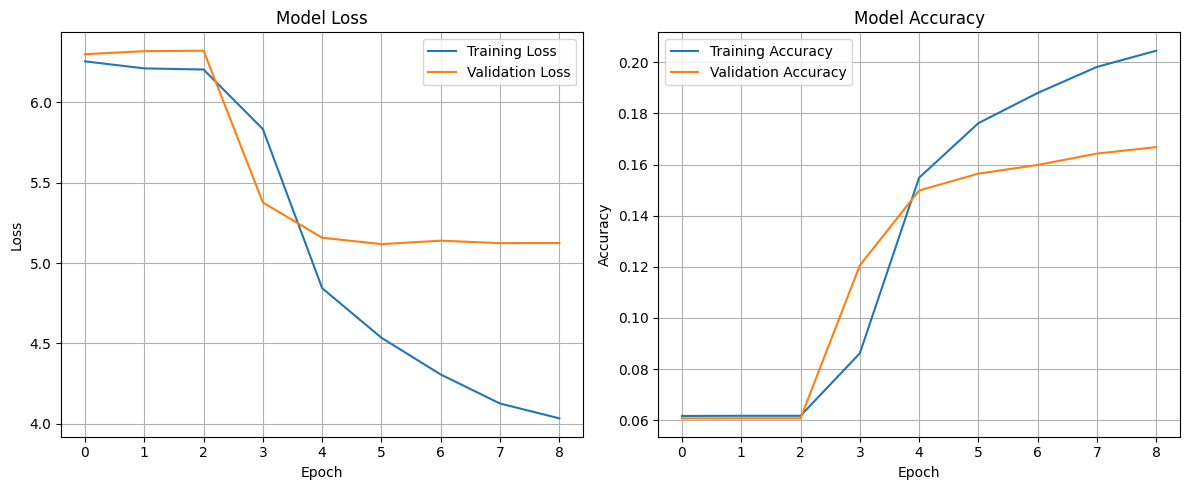

In [ ]:
# Cell 7: Plot training metrics
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Cell 8: Save the model
model.save('pride_and_prejudice_model.keras')
print("Model saved as 'pride_and_prejudice.keras'")

Model saved as 'pride_and_prejudice.keras'


In [ ]:
def generate_text(model, sp, prompt, num_tokens=100, temperature=1.0):
    """
    Generate text autoregressively.

    Args:
        temperature: Controls randomness
            - Low (0.1-0.5): Focused, repetitive
            - Medium (0.7-1.0): Balanced
            - High (1.5+): Creative, chaotic
    """
    # Encode the prompt
    input_ids = sp.encode_as_ids(prompt)

    # Rest of your generation code stays the same...
    if len(input_ids) < seq_length:
        padding_length = seq_length - len(input_ids)
        input_ids = [0] * padding_length + input_ids
    else:
        padding_length = 0
        input_ids = input_ids[-seq_length:]

    # Generated tokens
    generated_ids = list(input_ids[padding_length:])

    # Generate text token by token
    for _ in range(num_tokens):
        x = np.array([input_ids])
        predictions = model.predict(x, verbose=0)[0]
        logits = predictions[-1]
        logits = logits / temperature
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / np.sum(exp_logits)
        next_token = np.random.choice(len(probs), p=probs)
        generated_ids.append(next_token)
        input_ids = input_ids[1:] + [next_token]

    # Decode the generated sequence
    generated_text = sp.decode(generated_ids)

    return generated_text

In [ ]:
# Cell 10: Generate sample text
prompts = [
    "Elizabeth",
    "Mr. Darcy",
    "The general prejudice",
    "A letter arrived"
]

for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model, sp, prompt, num_tokens=100, temperature=0.6) # temp: 0.3 --> Toistaa "and" ja "I am sure" sekä paljon pilkkuja
    print(generated)


Prompt: Elizabeth
Elizabeth’s opinion of it had been much feelings, but by the opportunity of the following presents, and was at the angel of the affection of the sight of the world, were more contemplation that he was looked to than as to be broken. The good, however, and it was a very deal of their character, of the whole walk, who was to be true, and Jane would be the object of so many. She was an hurry, however, of his dear, though it had not to

Prompt: Mr. Darcy
Mr. Darcy, and to have been able by the apartments.” “I am not give me this husband, I am a great opinion of Mr. Darcy and Mr. Collins about you. Is me, I am determined, you are very right, I have not not say, for I am then, but you are never aware of the probable of falling to make him. But I am all, I cannot be forgot, that you is no strong a word to the honour of my ladies’s civility, if

Prompt: The general prejudice
The general prejudice, and was at a comfort in the highest party, and so satisfied to draw with a man

In [ ]:
# Cell 11: Load model (if you're starting a new session)
# Uncomment these lines to load a previously saved model
"""
# Load saved model
model = keras.models.load_model('pride_and_prejudice_model.keras')

# Load SentencePiece tokenizer
sp = spm.SentencePieceProcessor()
sp.load('pride_and_prejudice.model')

# Test generation
prompt = "Mieleni minun tekevi"
generated = generate_text(model, sp, prompt, num_tokens=150, temperature=1.0)
print(generated)
"""